# Tomato Disease Classification - Model Comparison (EfficientNet-B0 / MobileNetV3 / ResNet50)

## 1. Setup and GPU check

In [34]:
import os, io, json, random, time, copy, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED         = 42
IMG_SIZE     = 224
BATCH_SIZE   = 32
NUM_WORKERS  = 0
EPOCHS_HEAD  = 3
EPOCHS_FT    = 8
LR_HEAD      = 1e-3
LR_FT        = 1e-4
WEIGHT_DECAY = 1e-4
PRETRAINED   = True
MODEL_NAMES  = ['efficientnet_b0', 'mobilenet_v3_large', 'resnet50']
OUT_DIR      = Path('/kaggle/working')

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('torch:', torch.__version__)
print('device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), '| count:', torch.cuda.device_count())
else:
    print('No GPU found - enable it from Settings > Accelerator')

torch: 2.11.0+cu128
device: cuda
GPU: Tesla T4 | count: 2


## 2. Locate dataset and tomato classes

In [2]:
def find_color_dir(root='/kaggle/input'):
    candidates = []
    for dirpath, dirnames, _ in os.walk(root):
        if any(d.startswith('Tomato') for d in dirnames):
            candidates.append(Path(dirpath))
    color = [c for c in candidates if c.name.lower() == 'color']
    if color:
        return sorted(color)[0]
    if candidates:
        return sorted(candidates)[0]
    raise FileNotFoundError('No folder with Tomato classes found - add the dataset in Input')

DATA_DIR = find_color_dir()
print('DATA_DIR =', DATA_DIR)
if DATA_DIR.name.lower() != 'color':
    print('WARNING: the selected folder is not named "color"')

tomato_classes = sorted([d.name for d in DATA_DIR.iterdir() if d.is_dir() and d.name.startswith('Tomato')])
class_to_idx = {c: i for i, c in enumerate(tomato_classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
NUM_CLASSES  = len(tomato_classes)
short_names  = [c.replace('Tomato___', '') for c in tomato_classes]

print(f'\nNumber of tomato classes: {NUM_CLASSES}')
for c in tomato_classes:
    print(' -', c)

DATA_DIR = /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color

Number of tomato classes: 10
 - Tomato___Bacterial_spot
 - Tomato___Early_blight
 - Tomato___Late_blight
 - Tomato___Leaf_Mold
 - Tomato___Septoria_leaf_spot
 - Tomato___Spider_mites Two-spotted_spider_mite
 - Tomato___Target_Spot
 - Tomato___Tomato_Yellow_Leaf_Curl_Virus
 - Tomato___Tomato_mosaic_virus
 - Tomato___healthy


## 3. Dataset audit (unreadable files, exact duplicates)

In [5]:
IMG_EXT = {'.jpg', '.jpeg', '.png'}

# Collect image paths
records = [
    (str(p), class_to_idx[c], c)
    for c in tomato_classes
    for p in (DATA_DIR / c).iterdir()
    if p.suffix.lower() in IMG_EXT
]

df = pd.DataFrame(records, columns=['path', 'label', 'class_name'])

print('Images found:', len(df))


# Check images and calculate hashes
bad = []
md5s = {}

for i, pth in enumerate(df['path']):

    try:
        with open(pth, 'rb') as f:

            # Calculate hash
            md5 = hashlib.file_digest(f, 'md5').hexdigest()

        # Verify image
        with Image.open(pth) as img:
            img.verify()

        md5s[pth] = md5

    except Exception:
        bad.append(pth)

    if (i + 1) % 1000 == 0:
        print(f'Checked {i + 1}/{len(df)} images')


# Remove corrupted images
df = df[~df['path'].isin(bad)].copy()

df['md5'] = df['path'].map(md5s)


# Detect duplicates
dup_mask = df.duplicated('md5', keep=False)

conflicts = int(
    df[dup_mask].groupby('md5')['label'].nunique().gt(1).sum()
)

n_before = len(df)

df = df.drop_duplicates('md5', keep='first').reset_index(drop=True)


# Results
print('Unreadable files removed:', len(bad))
print('Exact duplicates removed:', n_before - len(df))
print('Duplicate groups with label conflict:', conflicts)
print('Images used:', len(df))

Images found: 18160
Checked 1000/18160 images
Checked 2000/18160 images
Checked 3000/18160 images
Checked 4000/18160 images
Checked 5000/18160 images
Checked 6000/18160 images
Checked 7000/18160 images
Checked 8000/18160 images
Checked 9000/18160 images
Checked 10000/18160 images
Checked 11000/18160 images
Checked 12000/18160 images
Checked 13000/18160 images
Checked 14000/18160 images
Checked 15000/18160 images
Checked 16000/18160 images
Checked 17000/18160 images
Checked 18000/18160 images
Unreadable files removed: 0
Exact duplicates removed: 14
Duplicate groups with label conflict: 0
Images used: 18146


## 4. Class distribution and samples

,count
class_name,
Tomato___Bacterial_spot,2127
Tomato___Early_blight,1000
Tomato___Late_blight,1901
Tomato___Leaf_Mold,952
Tomato___Septoria_leaf_spot,1771
Tomato___Spider_mites Two-spotted_spider_mite,1676
Tomato___Target_Spot,1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
Tomato___Tomato_mosaic_virus,373


/tmp/ipykernel_49/3375784775.py:8: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


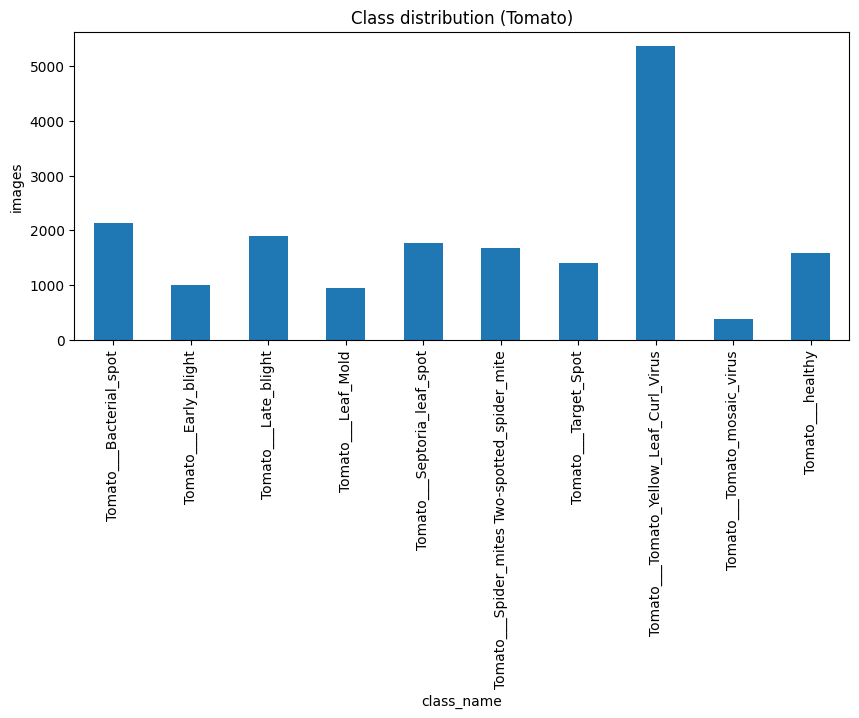

Largest / smallest class ratio: 14.4x


In [6]:
counts = df['class_name'].value_counts().sort_index()
display(counts.to_frame('count'))

plt.figure(figsize=(10, 4))
counts.plot(kind='bar')
plt.title('Class distribution (Tomato)')
plt.ylabel('images')
plt.tight_layout(); plt.show()

print(f'Largest / smallest class ratio: {counts.max() / counts.min():.1f}x')

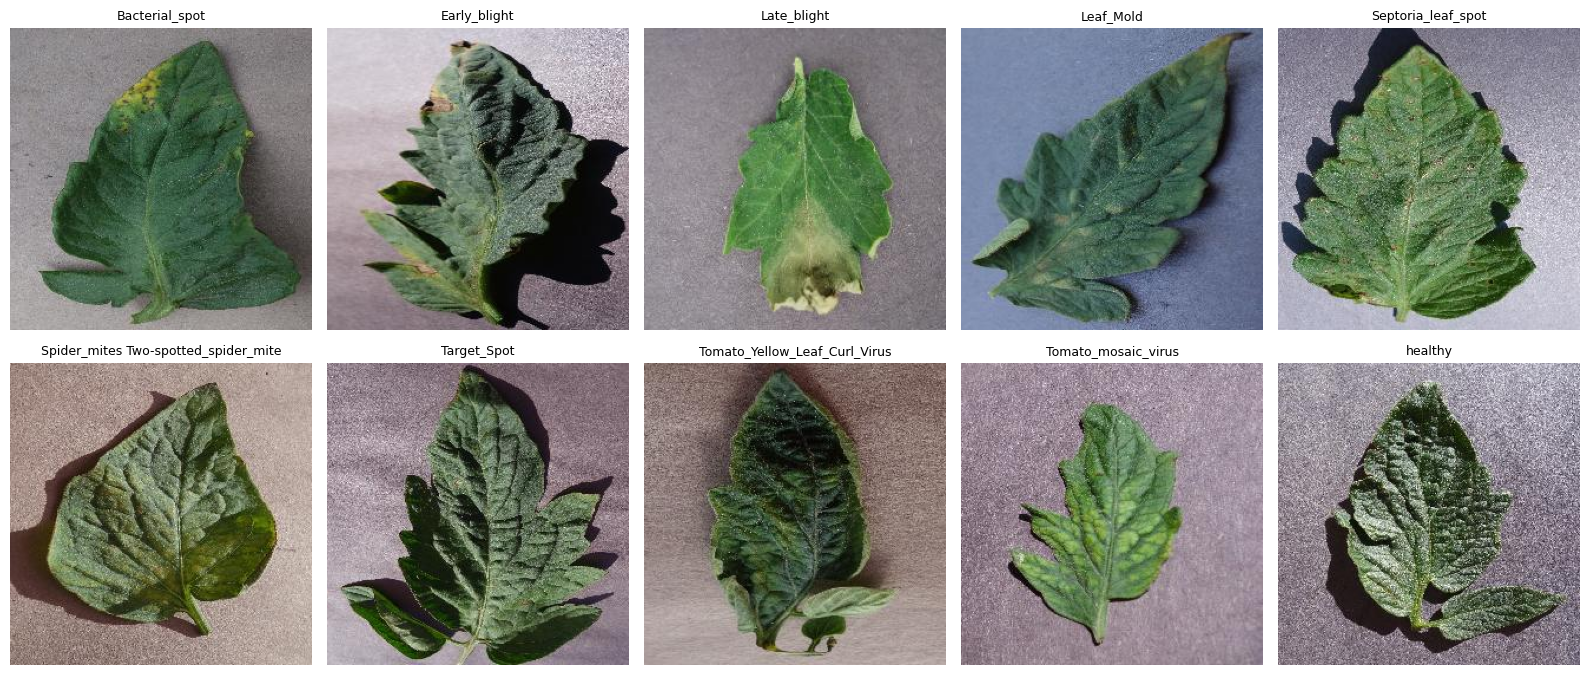

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, c in zip(axes.ravel(), tomato_classes):
    row = df[df.class_name == c].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(row.path).convert('RGB'))
    ax.set_title(c.replace('Tomato___', ''), fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Train / val / test split (70 / 15 / 15, stratified)

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{name:5s}: {len(d)} images')

train_df.to_csv(OUT_DIR / 'train.csv', index=False)
val_df.to_csv(OUT_DIR / 'val.csv', index=False)
test_df.to_csv(OUT_DIR / 'test.csv', index=False)

train: 12702 images
val  : 2722 images
test : 2722 images


## 6. Datasets, transforms and dataloaders

In [35]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class LeafDataset(Dataset):
    def __init__(self, frame, tfms):
        self.paths  = frame['path'].tolist()
        self.labels = frame['label'].tolist()
        self.tfms   = tfms
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tfms(img), self.labels[i]

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                 pin_memory=(device.type == 'cuda'), persistent_workers=(NUM_WORKERS > 0))
train_loader = DataLoader(LeafDataset(train_df, train_tfms), shuffle=True,  **loader_kw)
val_loader   = DataLoader(LeafDataset(val_df,   eval_tfms),  shuffle=False, **loader_kw)
test_loader  = DataLoader(LeafDataset(test_df,  eval_tfms),  shuffle=False, **loader_kw)

xb, yb = next(iter(train_loader))
print('batch:', xb.shape, yb.shape)

batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


In [10]:
train_counts  = train_df['label'].value_counts().sort_index().values
class_weights = torch.tensor(len(train_df) / (NUM_CLASSES * train_counts), dtype=torch.float32).to(device)
criterion     = nn.CrossEntropyLoss(weight=class_weights)
print(dict(zip(short_names, class_weights.cpu().numpy().round(2))))

{'Bacterial_spot': np.float32(0.85), 'Early_blight': np.float32(1.81), 'Late_blight': np.float32(0.95), 'Leaf_Mold': np.float32(1.91), 'Septoria_leaf_spot': np.float32(1.02), 'Spider_mites Two-spotted_spider_mite': np.float32(1.08), 'Target_Spot': np.float32(1.29), 'Tomato_Yellow_Leaf_Curl_Virus': np.float32(0.34), 'Tomato_mosaic_virus': np.float32(4.87), 'healthy': np.float32(1.15)}


## 7. Model factory

In [11]:
def build_model(name, num_classes, pretrained=PRETRAINED):
    if name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    elif name == 'mobilenet_v3_large':
        w = models.MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.mobilenet_v3_large(weights=w)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
    elif name == 'resnet50':
        w = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.resnet50(weights=w)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    else:
        raise ValueError(name)
    return m

def head_module(m, name):
    return m.fc if name == 'resnet50' else m.classifier

def set_backbone_trainable(m, name, trainable):
    head_ids = {id(p) for p in head_module(m, name).parameters()}
    for p in m.parameters():
        p.requires_grad = True if id(p) in head_ids else trainable

for n in MODEL_NAMES:
    m = build_model(n, NUM_CLASSES)
    print(f'{n:20s} params: {sum(p.numel() for p in m.parameters()) / 1e6:.2f}M')
del m

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 210MB/s]


efficientnet_b0      params: 4.02M
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 239MB/s]


mobilenet_v3_large   params: 4.21M
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 251MB/s]


resnet50             params: 23.53M


## 8. Training and evaluation functions

In [24]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    loss_sum, n = 0.0, 0
    all_preds, all_labels = [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out  = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            loss_sum += loss.item() * x.size(0)
            n        += x.size(0)
            all_preds.append(out.argmax(1).cpu())
            all_labels.append(y.cpu())
    preds  = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return loss_sum / n, accuracy_score(labels, preds), f1_score(labels, preds, average='macro')

def train_model(name):
    seed_everything(SEED)
    model  = build_model(name, NUM_CLASSES).to(device)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    ckpt   = OUT_DIR / f'best_{name}.pth'
    best_f1, history = -1.0, []

    stages = [('head', EPOCHS_HEAD, False, LR_HEAD), ('finetune', EPOCHS_FT, True, LR_FT)]
    for stage, epochs, trainable, lr in stages:
        set_backbone_trainable(model, name, trainable)
        params = [p for p in model.parameters() if p.requires_grad]
        opt    = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
        sched  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if stage == 'finetune' else None
        for ep in range(1, epochs + 1):
            t0 = time.time()
            tr_loss, tr_acc, tr_f1 = run_epoch(model, train_loader, opt, scaler)
            va_loss, va_acc, va_f1 = run_epoch(model, val_loader)
            if sched: sched.step()
            history.append(dict(stage=stage, epoch=len(history) + 1,
                                train_loss=tr_loss, val_loss=va_loss,
                                train_acc=tr_acc, val_acc=va_acc,
                                train_f1=tr_f1, val_f1=va_f1))
            tag = ''
            if va_f1 > best_f1:
                best_f1 = va_f1
                torch.save(model.state_dict(), ckpt)
                tag = '  <- best'
            print(f'[{name}][{stage}] ep {ep}/{epochs} | train loss {tr_loss:.4f} f1 {tr_f1:.4f} | '
                  f'val loss {va_loss:.4f} f1 {va_f1:.4f} | {time.time() - t0:.0f}s{tag}')

    model.load_state_dict(torch.load(ckpt, map_location=device))
    return model, history

In [28]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        out = model(x.to(device, non_blocking=True))
        probs.append(torch.softmax(out.float(), dim=1).cpu())
        labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

@torch.no_grad()
def measure_latency(model, dev, n_warmup=10, n_runs=100):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=dev)
    for _ in range(n_warmup):
        m(x)
    if dev.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n_runs):
        m(x)
    if dev.type == 'cuda':
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_runs * 1000

def run_experiment(name):
    t0 = time.time()
    model, history = train_model(name)
    train_min = (time.time() - t0) / 60

    probs, labels = predict(model, test_loader)
    preds  = probs.argmax(1)
    cls_ids = list(range(NUM_CLASSES))
    acc = accuracy_score(labels, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    _, _, f1_cls, _  = precision_recall_fscore_support(labels, preds, average=None, labels=cls_ids, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=cls_ids)

    model = model.cpu()
    lat_cpu = measure_latency(model, torch.device('cpu'), n_warmup=5, n_runs=50)
    lat_gpu = measure_latency(model, torch.device('cuda')) if torch.cuda.is_available() else None

    result = dict(
        model=name,
        accuracy=float(acc), precision_macro=float(prec), recall_macro=float(rec), f1_macro=float(f1),
        per_class_f1=[float(v) for v in f1_cls],
        confusion_matrix=cm.tolist(),
        params_m=sum(p.numel() for p in model.parameters()) / 1e6,
        size_mb=(OUT_DIR / f'best_{name}.pth').stat().st_size / 1e6,
        latency_cpu_ms=float(lat_cpu),
        latency_gpu_ms=None if lat_gpu is None else float(lat_gpu),
        train_minutes=float(train_min),
        history=history,
    )
    with open(OUT_DIR / f'results_{name}.json', 'w') as f:
        json.dump(result, f, indent=2)

    print(f'\n{name}: acc {acc:.4f} | macro P {prec:.4f} R {rec:.4f} F1 {f1:.4f} | '
          f'cpu {lat_cpu:.1f} ms | gpu {lat_gpu if lat_gpu is None else round(lat_gpu, 1)} ms | {train_min:.1f} min')
    print(classification_report(labels, preds, target_names=short_names, digits=4, zero_division=0))

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

## 9. Experiment: EfficientNet-B0

In [29]:
res_effnet = run_experiment('efficientnet_b0')

[efficientnet_b0][head] ep 1/3 | train loss 0.9972 f1 0.7080 | val loss 0.5027 f1 0.8437 | 47s  <- best
[efficientnet_b0][head] ep 2/3 | train loss 0.5663 f1 0.8134 | val loss 0.4074 f1 0.8661 | 35s  <- best
[efficientnet_b0][head] ep 3/3 | train loss 0.4935 f1 0.8232 | val loss 0.3429 f1 0.8943 | 36s  <- best
[efficientnet_b0][finetune] ep 1/8 | train loss 0.2250 f1 0.9190 | val loss 0.0884 f1 0.9634 | 57s  <- best
[efficientnet_b0][finetune] ep 2/8 | train loss 0.0963 f1 0.9662 | val loss 0.0504 f1 0.9814 | 43s  <- best
[efficientnet_b0][finetune] ep 3/8 | train loss 0.0602 f1 0.9772 | val loss 0.0386 f1 0.9856 | 43s  <- best
[efficientnet_b0][finetune] ep 4/8 | train loss 0.0435 f1 0.9836 | val loss 0.0349 f1 0.9871 | 44s  <- best
[efficientnet_b0][finetune] ep 5/8 | train loss 0.0336 f1 0.9867 | val loss 0.0333 f1 0.9877 | 43s  <- best
[efficientnet_b0][finetune] ep 6/8 | train loss 0.0299 f1 0.9893 | val loss 0.0271 f1 0.9913 | 43s  <- best
[efficientnet_b0][finetune] ep 7/8 | tra

## 10. Experiment: MobileNetV3-Large

In [30]:
res_mobilenet = run_experiment('mobilenet_v3_large')

[mobilenet_v3_large][head] ep 1/3 | train loss 0.6540 f1 0.7606 | val loss 0.4108 f1 0.8578 | 42s  <- best
[mobilenet_v3_large][head] ep 2/3 | train loss 0.3754 f1 0.8556 | val loss 0.2708 f1 0.9173 | 35s  <- best
[mobilenet_v3_large][head] ep 3/3 | train loss 0.3393 f1 0.8730 | val loss 0.2288 f1 0.8997 | 34s
[mobilenet_v3_large][finetune] ep 1/8 | train loss 0.1486 f1 0.9418 | val loss 0.0930 f1 0.9634 | 48s  <- best
[mobilenet_v3_large][finetune] ep 2/8 | train loss 0.0710 f1 0.9728 | val loss 0.0556 f1 0.9803 | 38s  <- best
[mobilenet_v3_large][finetune] ep 3/8 | train loss 0.0437 f1 0.9826 | val loss 0.0432 f1 0.9856 | 38s  <- best
[mobilenet_v3_large][finetune] ep 4/8 | train loss 0.0325 f1 0.9871 | val loss 0.0431 f1 0.9866 | 38s  <- best
[mobilenet_v3_large][finetune] ep 5/8 | train loss 0.0236 f1 0.9908 | val loss 0.0308 f1 0.9910 | 37s  <- best
[mobilenet_v3_large][finetune] ep 6/8 | train loss 0.0200 f1 0.9934 | val loss 0.0274 f1 0.9925 | 38s  <- best
[mobilenet_v3_large][f

## 11. Experiment: ResNet50

In [36]:
res_resnet = run_experiment('resnet50')

[resnet50][head] ep 1/3 | train loss 1.0552 f1 0.6411 | val loss 0.8809 f1 0.6407 | 101s  <- best
[resnet50][head] ep 2/3 | train loss 0.6346 f1 0.7731 | val loss 0.6561 f1 0.7574 | 99s  <- best
[resnet50][head] ep 3/3 | train loss 0.5340 f1 0.8014 | val loss 0.5747 f1 0.7808 | 99s  <- best
[resnet50][finetune] ep 1/8 | train loss 0.2520 f1 0.9015 | val loss 0.0948 f1 0.9677 | 128s  <- best
[resnet50][finetune] ep 2/8 | train loss 0.1142 f1 0.9557 | val loss 0.0692 f1 0.9824 | 127s  <- best
[resnet50][finetune] ep 3/8 | train loss 0.0666 f1 0.9743 | val loss 0.0582 f1 0.9834 | 128s  <- best
[resnet50][finetune] ep 4/8 | train loss 0.0462 f1 0.9820 | val loss 0.0556 f1 0.9826 | 126s
[resnet50][finetune] ep 5/8 | train loss 0.0308 f1 0.9878 | val loss 0.0388 f1 0.9894 | 124s  <- best
[resnet50][finetune] ep 6/8 | train loss 0.0176 f1 0.9929 | val loss 0.0303 f1 0.9930 | 123s  <- best
[resnet50][finetune] ep 7/8 | train loss 0.0092 f1 0.9966 | val loss 0.0282 f1 0.9934 | 131s  <- best
[re

## 12. Comparison table

In [37]:
results = {}
for n in MODEL_NAMES:
    fp = OUT_DIR / f'results_{n}.json'
    if fp.exists():
        with open(fp) as f:
            results[n] = json.load(f)
print('Loaded:', list(results))

cols = ['model', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
        'latency_cpu_ms', 'latency_gpu_ms', 'params_m', 'size_mb', 'train_minutes']
cmp_df = (pd.DataFrame([{c: r[c] for c in cols} for r in results.values()])
            .sort_values('f1_macro', ascending=False).reset_index(drop=True))
display(cmp_df.round(4))
cmp_df.to_csv(OUT_DIR / 'model_comparison.csv', index=False)

Loaded: ['efficientnet_b0', 'mobilenet_v3_large', 'resnet50']


,model,accuracy,precision_macro,recall_macro,f1_macro,latency_cpu_ms,latency_gpu_ms,params_m,size_mb,train_minutes
0,resnet50,0.9956,0.9947,0.9961,0.9954,129.3842,6.2549,23.5285,94.4340,22.0765
1,efficientnet_b0,0.9934,0.9906,0.9950,0.9928,33.7812,7.8923,4.0204,16.3846,7.9837
2,mobilenet_v3_large,0.9934,0.9894,0.9939,0.9916,18.5309,5.9511,4.2148,17.0699,7.0170


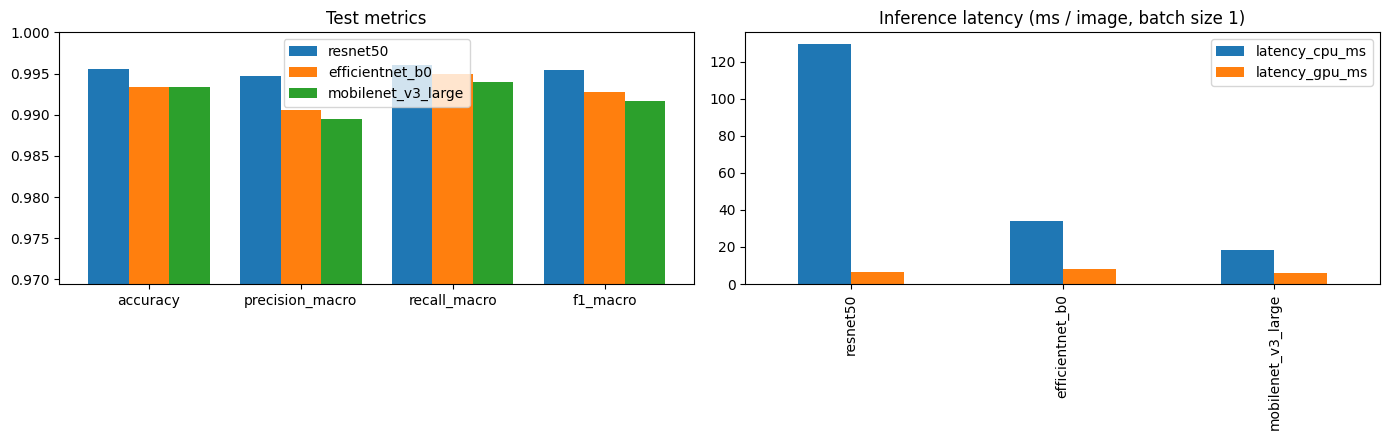

In [38]:
metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
x = np.arange(len(metrics))
w = 0.8 / len(cmp_df)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, row in cmp_df.iterrows():
    ax[0].bar(x + i * w, [row[m] for m in metrics], w, label=row['model'])
ax[0].set_xticks(x + w * (len(cmp_df) - 1) / 2)
ax[0].set_xticklabels(metrics)
ax[0].set_ylim(max(0, cmp_df[metrics].min().min() - 0.02), 1.0)
ax[0].set_title('Test metrics')
ax[0].legend()

cmp_df.set_index('model')[['latency_cpu_ms', 'latency_gpu_ms']].plot(kind='bar', ax=ax[1])
ax[1].set_title('Inference latency (ms / image, batch size 1)')
ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

## 13. Confusion matrices

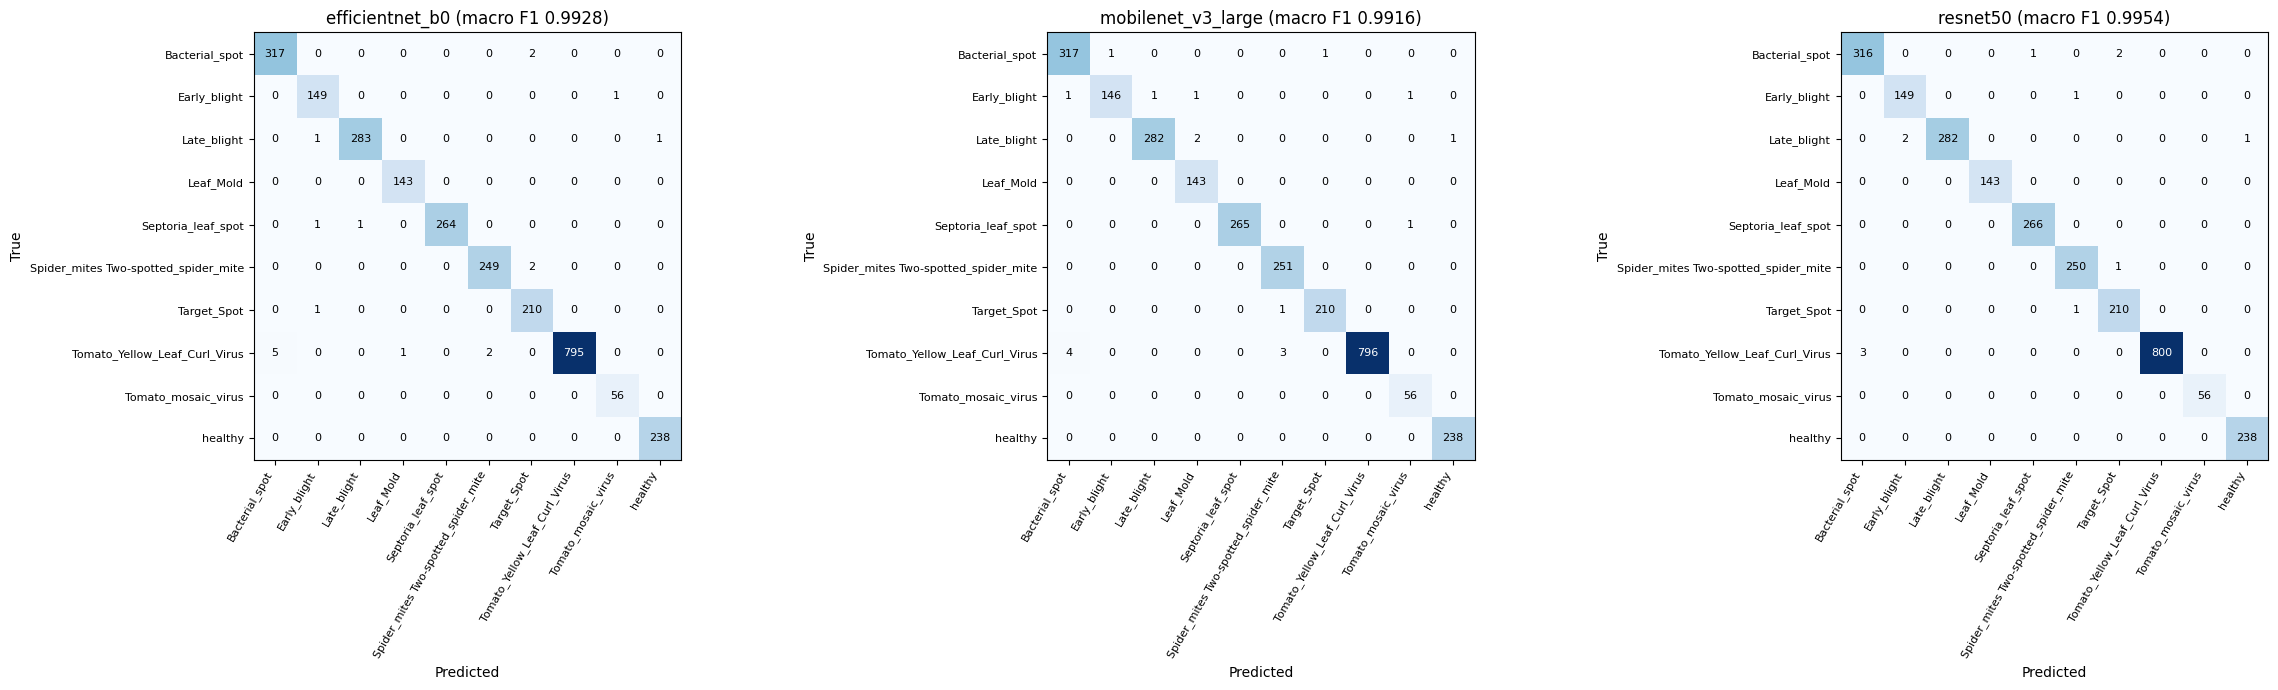

In [39]:
fig, axes = plt.subplots(1, len(results), figsize=(8 * len(results), 7))
axes = np.atleast_1d(axes)
for ax, (n, r) in zip(axes, results.items()):
    cm = np.array(r['confusion_matrix'])
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(short_names, rotation=60, ha='right', fontsize=8)
    ax.set_yticklabels(short_names, fontsize=8)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{n} (macro F1 {r["f1_macro"]:.4f})')
plt.tight_layout(); plt.show()

## 14. Per-class F1 and training curves

,efficientnet_b0,mobilenet_v3_large,resnet50
Bacterial_spot,0.9891,0.9891,0.9906
Early_blight,0.9868,0.9832,0.9900
Late_blight,0.9947,0.9930,0.9947
Leaf_Mold,0.9965,0.9896,1.0000
Septoria_leaf_spot,0.9962,0.9981,0.9981
Spider_mites Two-spotted_spider_mite,0.9920,0.9921,0.9940
Target_Spot,0.9882,0.9953,0.9906
Tomato_Yellow_Leaf_Curl_Virus,0.9950,0.9956,0.9981
Tomato_mosaic_virus,0.9912,0.9825,1.0000
healthy,0.9979,0.9979,0.9979


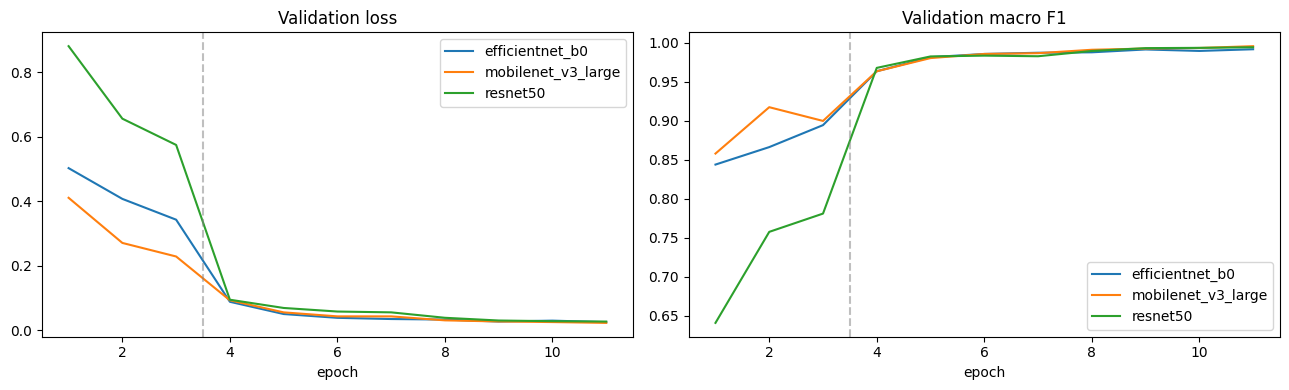

In [40]:
pc = pd.DataFrame({n: r['per_class_f1'] for n, r in results.items()}, index=short_names)
display(pc.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, r in results.items():
    h = pd.DataFrame(r['history'])
    ax[0].plot(h['epoch'], h['val_loss'], label=n)
    ax[1].plot(h['epoch'], h['val_f1'], label=n)
ax[0].set_title('Validation loss'); ax[1].set_title('Validation macro F1')
for a in ax:
    a.axvline(EPOCHS_HEAD + 0.5, color='gray', ls='--', alpha=0.5)
    a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

## 15. Export the selected model (set FINAL_MODEL first)

In [67]:
with open(OUT_DIR / 'labels.json', 'w', encoding='utf-8') as f:
    json.dump(
        [idx_to_class[i] for i in range(NUM_CLASSES)],
        f,
        ensure_ascii=False,
        indent=2
    )

for FINAL_MODEL in MODEL_NAMES:

    results_path = OUT_DIR / f'results_{FINAL_MODEL}.json'

    with open(results_path) as f:
        final = json.load(f)

    model_card = {
        'model': FINAL_MODEL,
        'crop': 'tomato',
        'dataset': 'PlantVillage (color)',
        'num_classes': NUM_CLASSES,
        'input': {
            'size': [IMG_SIZE, IMG_SIZE],
            'channels': 'RGB',
            'layout': 'NCHW',
            'scale': '0-1 (divide by 255)',
            'mean': IMAGENET_MEAN,
            'std': IMAGENET_STD,
            'resize': 'direct resize to 224x224 (no crop)'
        },
        'test_accuracy': final['accuracy'],
        'test_macro_precision': final['precision_macro'],
        'test_macro_recall': final['recall_macro'],
        'test_macro_f1': final['f1_macro'],
        'latency_cpu_ms': final['latency_cpu_ms'],
    }

    output_path = OUT_DIR / f'model_card_{FINAL_MODEL}.json'

    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(model_card, f, ensure_ascii=False, indent=2)

    print(f"\n{'='*40}")
    print(f"Model Card: {FINAL_MODEL}")
    print(json.dumps(model_card, indent=2))

print("\nAll model cards generated successfully!")


Model Card: efficientnet_b0
{
  "model": "efficientnet_b0",
  "crop": "tomato",
  "dataset": "PlantVillage (color)",
  "num_classes": 10,
  "input": {
    "size": [
      224,
      224
    ],
    "channels": "RGB",
    "layout": "NCHW",
    "scale": "0-1 (divide by 255)",
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ],
    "resize": "direct resize to 224x224 (no crop)"
  },
  "test_accuracy": 0.9933872152828802,
  "test_macro_precision": 0.9905881960036551,
  "test_macro_recall": 0.9949857295922158,
  "test_macro_f1": 0.9927619132098433,
  "latency_cpu_ms": 33.781210940001074
}

Model Card: mobilenet_v3_large
{
  "model": "mobilenet_v3_large",
  "crop": "tomato",
  "dataset": "PlantVillage (color)",
  "num_classes": 10,
  "input": {
    "size": [
      224,
      224
    ],
    "channels": "RGB",
    "layout": "NCHW",
    "scale": "0-1 (divide by 255)",
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    

In [43]:
for name in MODEL_NAMES:
    path = OUT_DIR / f'results_{name}.json'

    with open(path, 'r') as f:
        result = json.load(f)

    print(f"\n===== {name} =====")
    print(f"Accuracy: {result['accuracy']:.4f}")
    print(f"Macro F1: {result['f1_macro']:.4f}")
    print(f"Precision: {result['precision_macro']:.4f}")
    print(f"Recall: {result['recall_macro']:.4f}")
    print(f"CPU Latency: {result['latency_cpu_ms']:.2f} ms")


===== efficientnet_b0 =====
Accuracy: 0.9934
Macro F1: 0.9928
Precision: 0.9906
Recall: 0.9950
CPU Latency: 33.78 ms

===== mobilenet_v3_large =====
Accuracy: 0.9934
Macro F1: 0.9916
Precision: 0.9894
Recall: 0.9939
CPU Latency: 18.53 ms

===== resnet50 =====
Accuracy: 0.9956
Macro F1: 0.9954
Precision: 0.9947
Recall: 0.9961
CPU Latency: 129.38 ms


In [68]:
import importlib, subprocess, sys
for pkg in ['onnx', 'onnxruntime']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

model_cpu = build_model(FINAL_MODEL, NUM_CLASSES, pretrained=False)
model_cpu.load_state_dict(torch.load(OUT_DIR / f'best_{FINAL_MODEL}.pth', map_location='cpu'))
model_cpu.eval()

dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
onnx_path = OUT_DIR / f'tomato_{FINAL_MODEL}.onnx'
export_kwargs = dict(input_names=['input'], output_names=['logits'],
                     dynamic_axes={'input': {0: 'batch'}, 'logits': {0: 'batch'}},
                     opset_version=17)
try:
    torch.onnx.export(model_cpu, dummy, str(onnx_path), dynamo=False, **export_kwargs)
except TypeError:
    torch.onnx.export(model_cpu, dummy, str(onnx_path), **export_kwargs)
print('saved:', onnx_path, f'({onnx_path.stat().st_size / 1e6:.1f} MB)')

/tmp/ipykernel_49/802734940.py:18: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, dummy, str(onnx_path), dynamo=False, **export_kwargs)


saved: /kaggle/working/tomato_resnet50.onnx (94.0 MB)


In [69]:
import onnxruntime as ort

sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
onnx_out  = sess.run(None, {'input': dummy.numpy()})[0]
torch_out = model_cpu(dummy).detach().numpy()
print('max abs diff:', np.abs(onnx_out - torch_out).max())

max abs diff: 2.861023e-06
